# Unidad IV · K-Means y PCA
Ulises González Coronado · Recursamiento ECBD 2026

Dataset Energy Efficiency de UCI. Ejecutar de arriba hacia abajo con el entorno del repositorio.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/preparacion_datos.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print('Proyecto:', ROOT.name)


Proyecto: REC_ECBD_2026_Gonzalez_Ulises


## 1. Selección y estandarización
Se usan seis variables físicas X1-X5 y X7. Se excluyen X6/X8 porque sus códigos nominales no representan distancias. Y1/Y2 solo describen los grupos después de entrenar. StandardScaler centra y escala cada variable.

In [2]:
from src.modelos_no_supervisados import analizar, VARIABLES
resultado = analizar()
display(resultado)

{'variables': ['X1', 'X2', 'X3', 'X4', 'X5', 'X7'], 'excluidas': {'X6': 'Código nominal de orientación', 'X8': 'Código nominal de distribución', 'Y1_Y2': 'Respuestas; solo se usan para describir grupos después'}, 'k_elegido': 2, 'criterio': 'Mayor silhouette entre k=2..8; menor k ante empate', 'silhouette': 0.5244404334792286, 'varianza_PC1_PC2': 0.8237984333178338, 'componentes_95_por_ciento': 3, 'ARI_otras_semillas': [1.0, 1.0, 1.0], 'n_registros': 768, 'alcance': 'Exploración de las 768 simulaciones, sin evaluación predictiva. La geometría domina y sus variables están correlacionadas.'}


{'variables': ['X1', 'X2', 'X3', 'X4', 'X5', 'X7'],
 'excluidas': {'X6': 'Código nominal de orientación',
  'X8': 'Código nominal de distribución',
  'Y1_Y2': 'Respuestas; solo se usan para describir grupos después'},
 'k_elegido': 2,
 'criterio': 'Mayor silhouette entre k=2..8; menor k ante empate',
 'silhouette': 0.5244404334792286,
 'varianza_PC1_PC2': 0.8237984333178338,
 'componentes_95_por_ciento': 3,
 'ARI_otras_semillas': [1.0, 1.0, 1.0],
 'n_registros': 768,
 'alcance': 'Exploración de las 768 simulaciones, sin evaluación predictiva. La geometría domina y sus variables están correlacionadas.'}

## 2. Número de grupos
Se compara k = 2..8 con 30 inicializaciones y semilla 42. Se elige el mayor silhouette. También se revisa la inercia para el codo. Silhouette no es porcentaje de aciertos.

,k,inercia,silhouette
0,2,1961.233560,0.524440
1,3,1547.502625,0.440350
2,4,1161.532984,0.386473
3,5,935.765229,0.409069
4,6,765.951925,0.417859
5,7,633.410509,0.433899
6,8,502.788671,0.464330


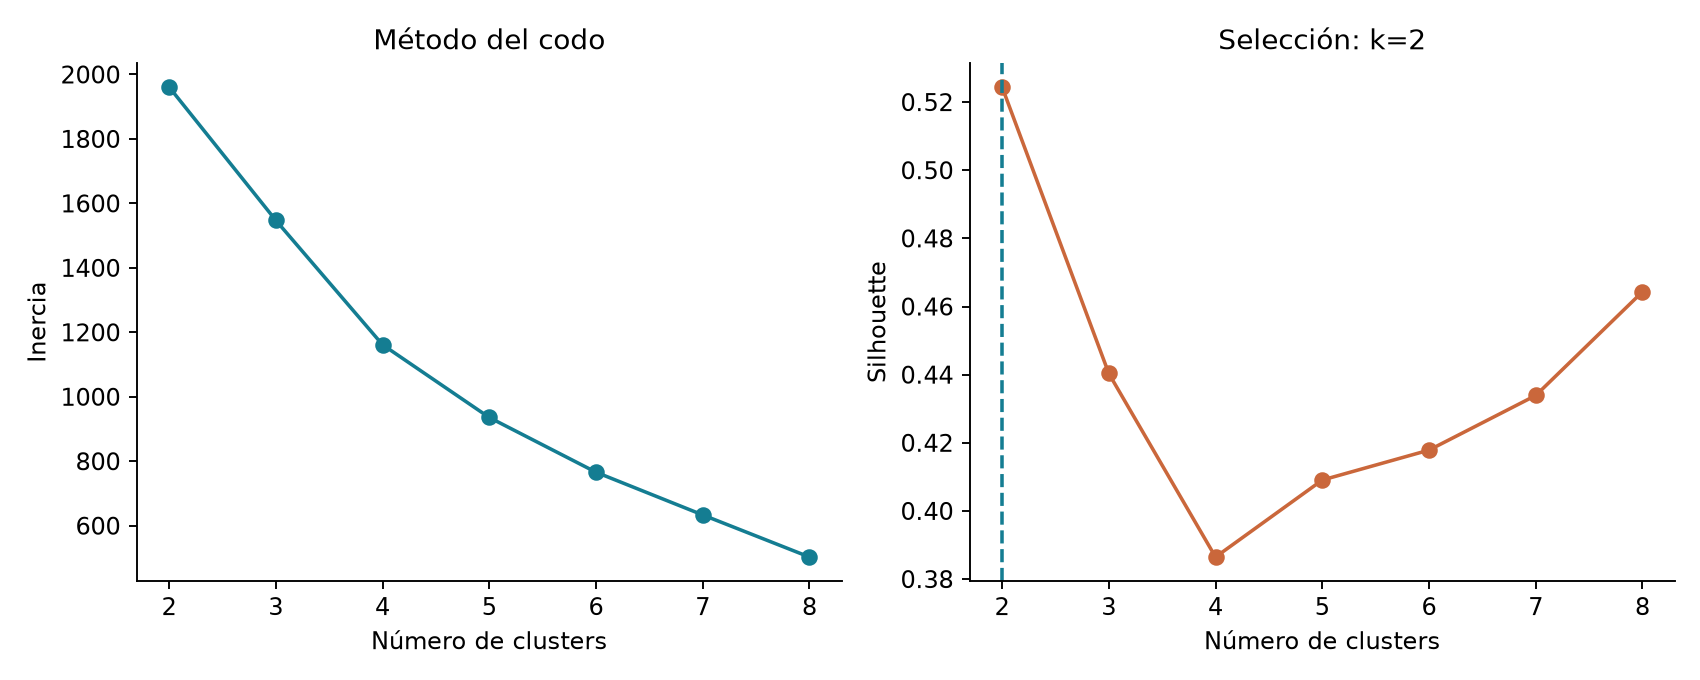

In [3]:
display(pd.read_csv(ROOT/'docs/evaluacion_clusters.csv'))
display(Image(filename=str(ROOT/'docs/figuras/05_seleccion_clusters.png')))

## 3. Caracterización
Dos grupos de 384 simulaciones corresponden a las alturas 3.5 y 7, junto con diferencias en geometría. Las medias de calefacción son aproximadamente 13.34 y 31.28. Y1/Y2 no se utilizaron para crear estos grupos.

In [4]:
display(pd.read_csv(ROOT/'data/processed/perfiles_clusters.csv'))
print('ARI con otras semillas:', resultado['ARI_otras_semillas'])

,id_cluster,registros,compacidad_media,superficie_media,pared_media,techo_medio,altura_media,cristal_medio,calefaccion_media,refrigeracion_media
0,1,384,0.676667,747.250000,306.25,220.500000,3.5,0.234375,13.338505,16.071432
1,2,384,0.851667,596.166667,330.75,132.708333,7.0,0.234375,31.275885,33.104089


ARI con otras semillas: [1.0, 1.0, 1.0]


## 4. PCA y varianza explicada
PCA usa la misma matriz estandarizada. Dos componentes explican 82.38% de la varianza; tres superan el 95%. La gráfica 2D pierde información. Las cargas indican qué variables contribuyen a cada eje; el signo puede invertirse sin cambiar la interpretación geométrica.

,componente,varianza_explicada,varianza_acumulada
0,PC1,0.617157,0.617157
1,PC2,0.206642,0.823798
2,PC3,0.166667,0.990465
3,PC4,0.008792,0.999257
4,PC5,0.000743,1.000000
5,PC6,0.000000,1.000000


,variable,PC1,PC2,PC3,PC4,PC5,PC6
0,X1,-4.959514e-01,-2.447347e-01,-6.940565e-17,-4.951698e-01,6.700328e-01,4.936507e-14
1,X2,5.017330e-01,2.315407e-01,-1.631614e-16,6.621217e-02,5.048820e-01,-6.598204e-01
2,X3,-3.251430e-02,8.942917e-01,8.514746e-17,-2.911152e-01,8.743935e-02,3.267898e-01
3,X4,5.049622e-01,-2.061208e-01,1.047438e-16,2.051623e-01,4.501004e-01,6.766428e-01
4,X5,-4.962380e-01,2.103580e-01,9.186548e-17,7.896728e-01,2.931112e-01,2.586820e-14
5,X7,4.290559e-17,-5.308892e-17,1.000000e+00,-9.280975e-17,4.736402e-17,-2.063567e-16


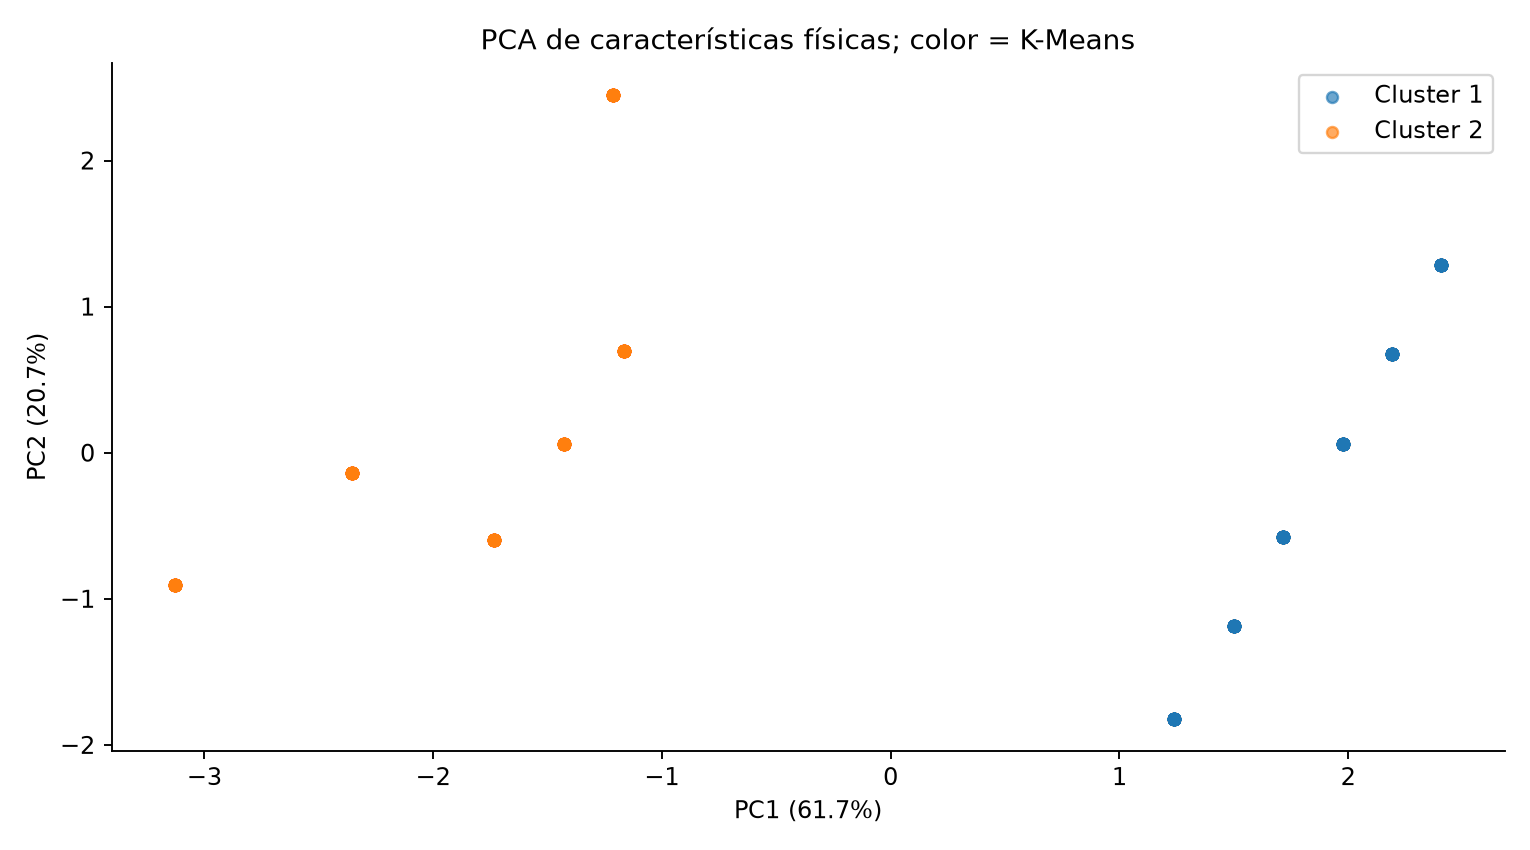

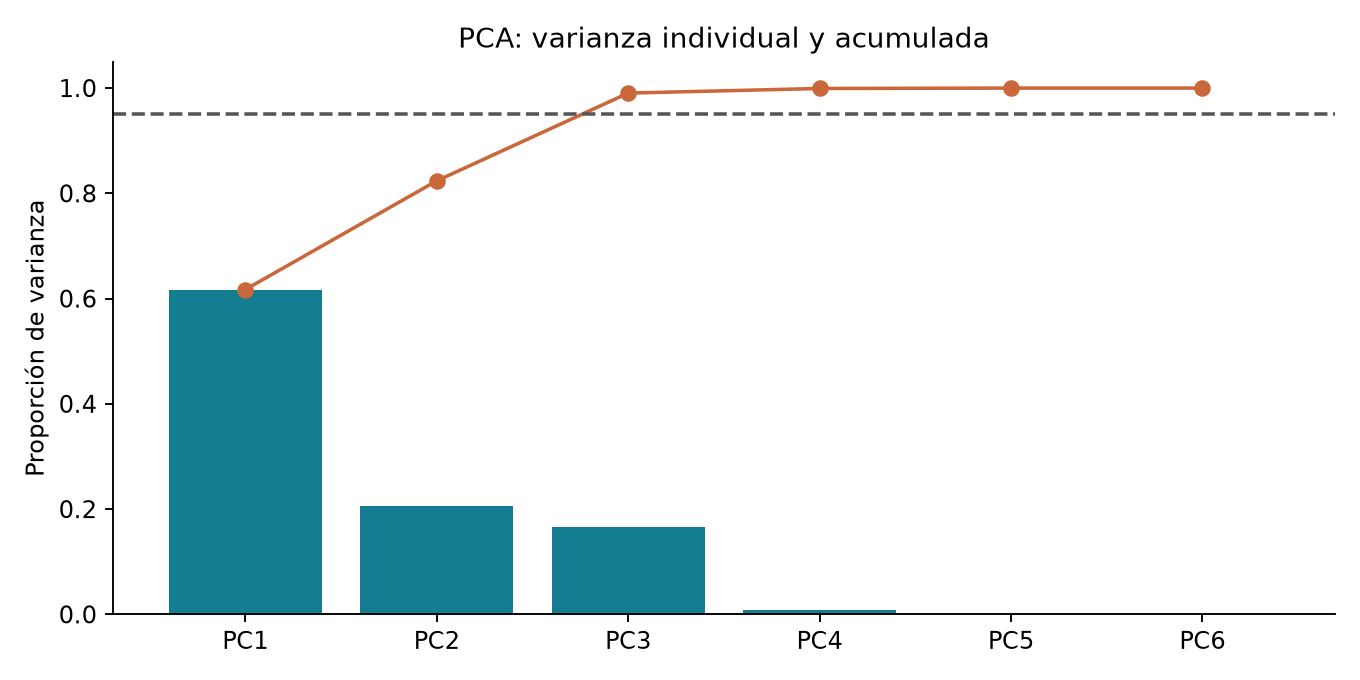

In [5]:
display(pd.read_csv(ROOT/'docs/varianza_pca.csv'))
display(pd.read_csv(ROOT/'docs/cargas_pca.csv'))
display(Image(filename=str(ROOT/'docs/figuras/06_pca_clusters.png')))
display(Image(filename=str(ROOT/'docs/figuras/07_varianza_pca.png')))

## 5. Conocimiento y decisiones
La estructura geométrica domina el agrupamiento; varias variables están correlacionadas. Los clusters sirven para organizar comparaciones entre diseños semejantes, no para certificar eficiencia. La estabilidad de semillas no demuestra validez externa. Se requieren mediciones reales y contexto climático para extrapolar.